# ERTH 2001 Lab 3: Density and Isostasy

This notebook reproduces Lab 3 from ERTH 2001 (Planet Earth) in Python. The lab was originally an Excel workbook plus a set of written calculations: measure the densities of basalt, granite, and peridotite; plot the heights and ages of stranded beaches left behind by postglacial rebound at Hudson Bay; and then use those densities in a floating-block calculation of how high oceanic and continental crust sit in the mantle, compared with Earth's bimodal topography, and of how thick the crust is under the Andes.

The same steps are followed here, one section at a time, so the concept each step was written to teach is the concept the code shows. Each code cell is introduced in plain words and followed by a short "what this shows," including the ideas a non-geologist interviewer is likely to ask about: what density we are averaging and why, what isostasy and Archimedes' principle have to do with mountains, the difference between Airy and Pratt compensation, what a stranded beach is recording, and why a linear rebound rate is only a first sketch.

The sample masses and volumes, the beach heights and ages, and the average densities below are the ones from the completed Excel workbook. A final check cell loads those spreadsheet densities and confirms that the Python results match them.

AI used: this notebook was built with help from an AI coding agent.


## Setup

**Density** is mass per volume. In this lab it is reported in g/cm³, the same units as the spreadsheet. Each rock type is represented by ten samples. The workbook does not do "total mass over total volume." It takes each sample's mass over its own volume and then averages those ten densities,

$$\bar{\rho} = \frac{1}{10}\sum_{i=1}^{10} \frac{m_i}{V_i}.$$

That is the arithmetic mean of the sample densities. A later extra section compares it with the bulk ratio $\sum m / \sum V$, which is a slightly different number.

**Isostasy** is the idea that Earth's crust is (on long enough timescales) in gravitational equilibrium, "floating" on the denser, deformable mantle the way a block of wood floats in water. Archimedes' principle says the weight of the block equals the weight of the fluid it displaces. For a crustal column of thickness $T$ and density $\rho_c$, floating in mantle of density $\rho_m$, that balance is

$$\rho_c T = \rho_m T_\mathrm{below},$$

so the part that sticks up above the mantle surface — the freeboard, $H_\mathrm{above}$ in the lab — is

$$H_\mathrm{above} = T - T_\mathrm{below} = T\left(1 - \frac{\rho_c}{\rho_m}\right) = T\frac{\rho_m - \rho_c}{\rho_m}.$$

Solving the other way, if you know the freeboard and want the whole thickness,

$$T = H_\mathrm{above}\frac{\rho_m}{\rho_m - \rho_c} = H_\mathrm{above}\left(1 + \frac{\rho_c}{\rho_m - \rho_c}\right).$$

Two classical pictures of how that equilibrium is arranged are worth telling apart, even though this lab only computes the floating-block version. In **Airy isostasy**, the density of the crust is about the same everywhere and mountains stand high because the crust is *thicker* — they have a deep root, like an iceberg. In **Pratt isostasy**, columns all go down to the same compensation depth and mountains stand high because the column is *lighter*. The Andes calculation in Part 3 thickens a granite column; that is the Airy picture.

A changing load uses the same idea. When a thick ice sheet sits on a continent it pushes the surface down; when the ice melts, the load is removed and the surface slowly rises. Old beaches that formed at sea level are left stranded above today's shoreline. The slope of a plot of beach height versus age is a rebound rate, in meters per year.

The next cell defines helpers for the average density, the floating-block freeboard, and the plots. It does not yet compute any of the lab numbers. Two thicknesses and one elevation used later come from the lab text, not from the spreadsheet: oceanic crust is taken as 5 km, average continental crust as 30 km, and the Andes as 5 km above sea level. Three elevations come from labels on the lab's hypsographic figure (Laboratory Manual in Physical Geology, AGI/NAGT, 2003): average height of land 0.84 km, average ocean depth 3.69 km, and their difference 4.53 km. The copyrighted figure itself is not reproduced in this folder.


In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle

DATADIR = Path("data")
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

# Thicknesses and the Andes elevation, quoted in the lab text.
OCEAN_CRUST_KM = 5.0
CONTINENT_CRUST_KM = 30.0
ANDES_ELEVATION_KM = 5.0

# Elevations labeled on the lab's hypsographic figure
# (Laboratory Manual in Physical Geology, AGI/NAGT, 2003).
# 0.84 + 3.69 = 4.53, the labeled land-to-seafloor difference.
AVG_LAND_HEIGHT_KM = 0.84
AVG_OCEAN_DEPTH_KM = 3.69
FIGURE_STEP_KM = AVG_LAND_HEIGHT_KM + AVG_OCEAN_DEPTH_KM  # 4.53 km

ROCK_COLORS = {
    "basalt": "#4C6B8A",
    "granite": "#C4A35A",
    "peridotite": "#8B3A3A",
}
TITLE = dict(fontsize=13, fontweight="bold", color="#1a1a1a")


def load_samples():
    """Load the ten mass-and-volume samples of each rock type."""
    df = pd.read_csv(DATADIR / "rock_samples.csv")
    return df


def load_beaches():
    """Load the Hudson Bay stranded-beach heights and ages."""
    return pd.read_csv(DATADIR / "hudson_bay_beaches.csv")


def mean_of_ratios(mass, volume):
    """Arithmetic mean of sample densities, the spreadsheet formula."""
    mass = np.asarray(mass, dtype=float)
    volume = np.asarray(volume, dtype=float)
    return float(np.mean(mass / volume))


def bulk_density(mass, volume):
    """Total mass over total volume — not what the spreadsheet uses."""
    mass = np.asarray(mass, dtype=float)
    volume = np.asarray(volume, dtype=float)
    return float(mass.sum() / volume.sum())


def freeboard(thickness, density_crust, density_mantle):
    """Height of a floating column that sits above the mantle surface.

    From Archimedes: rho_c * T = rho_m * T_below, so
    H_above = T * (rho_m - rho_c) / rho_m.
    """
    return thickness * (density_mantle - density_crust) / density_mantle


def thickness_from_freeboard(h_above, density_crust, density_mantle):
    """Invert the freeboard equation to get the whole column thickness."""
    return h_above * density_mantle / (density_mantle - density_crust)


def show_density_table(samples):
    """Display a per-rock table of the mean-of-ratios density."""
    rows = []
    for rock, grp in samples.groupby("rock", sort=False):
        rho = mean_of_ratios(grp["mass_g"], grp["volume_cm3"])
        rows.append({
            "Rock": rock,
            "N samples": len(grp),
            "Mean density (g/cm³)": rho,
            "Min sample (g/cm³)": float((grp["mass_g"] / grp["volume_cm3"]).min()),
            "Max sample (g/cm³)": float((grp["mass_g"] / grp["volume_cm3"]).max()),
        })
    table = pd.DataFrame(rows)
    display(
        table.style.format(
            {
                "Mean density (g/cm³)": "{:.4f}",
                "Min sample (g/cm³)": "{:.4f}",
                "Max sample (g/cm³)": "{:.4f}",
            }
        ).hide(axis="index")
    )
    return table


The helpers are now defined; no densities or freeboards have been computed yet. The constants above are the lab's given thicknesses and the figure labels, kept in one place so later cells can reuse them. Every plot will use the same rock colors.


## The data

The original workbook has three tabs. Part 1 is ten mass-and-volume samples each of basalt, granite, and peridotite, plus three average-density formulas. Part 2 is a list of stranded-beach heights (meters above present sea level) and radiocarbon ages (years before present) from Hudson Bay, Canada. Part 3 of the workbook has no calculated cells; those calculations were done by hand from the densities and the floating-block equations.

This folder keeps a trimmed copy:

- `data/rock_samples.csv` — rock type, sample number, mass (g), volume (cm³)
- `data/hudson_bay_beaches.csv` — height (m) and age (yr BP) for 19 beaches (a stray backslash in spreadsheet cell A21 was omitted)
- `data/excel_reference.xlsx` — the three average densities stored in the completed spreadsheet, used by the check cell

The next cell loads both tables and prints a short summary.


In [2]:
samples = load_samples()
beaches = load_beaches()

print(f"{len(samples)} rock samples "
      f"({', '.join(f'{n} {r}' for r, n in samples['rock'].value_counts().items())})")
print("mass in grams, volume in cm³, density will be g/cm³")
print()
print(f"{len(beaches)} stranded beaches")
print(
    f"  height: {beaches['height_m'].min():.1f} to "
    f"{beaches['height_m'].max():.1f} m above present sea level"
)
print(
    f"  age:    {beaches['age_yr_bp'].min():.0f} to "
    f"{beaches['age_yr_bp'].max():.0f} years before present"
)

display(samples.groupby("rock", sort=False)[["mass_g", "volume_cm3"]].agg(
    ["count", "min", "max"]
))


30 rock samples (10 basalt, 10 granite, 10 peridotite)
mass in grams, volume in cm³, density will be g/cm³

19 stranded beaches
  height: 1.0 to 249.4 m above present sea level
  age:    50 to 8393 years before present


mass_g              volume_cm3        
            count   min    max      count min max
rock                                             
basalt         10  28.2   78.3         10   9  25
granite        10  27.1   82.8         10  10  30
peridotite     10  31.3  130.0         10   9  40

The rock table is 30 samples, ten of each type, with mass in grams and volume in cubic centimeters. The beach table is 19 points, from a 1 m beach dated 50 years before present up to a 249.4 m beach dated 8393 years before present. Those ranges are what the next two parts will plot. The densities themselves are computed in Part 1, not read from a pre-filled column: each row's mass and volume are the inputs, and the spreadsheet's averages are saved only for the final check.


## Part 1 — Density of common crust and mantle rocks

Although Earth has many rock types, the lab treats three as the main constituents of the outer layers: **basalt** (the typical rock of oceanic crust), **granite** (the typical rock of continental crust), and **peridotite** (the typical rock of the upper mantle). The first task is to get a feel for their densities by averaging the ten samples of each.

The next cell computes each sample density as mass/volume, takes the mean of those ten values (the same formula as the spreadsheet), and plots the individual samples around that mean. The order from lightest to densest, and which layer each rock is taken to represent, will be visible from the numbers; the written table in the original lab asked for that classification, and the notebook will show the measurements without filling in a graded answer sheet.


Rock,N samples,Mean density (g/cm³),Min sample (g/cm³),Max sample (g/cm³)
basalt,10,3.0938,2.9500,3.1500
granite,10,2.7354,2.6100,2.8273
peridotite,10,3.3315,3.2100,3.4778



basalt       mean of ratios = 3.093779 g/cm³
granite      mean of ratios = 2.735366 g/cm³
peridotite   mean of ratios = 3.331475 g/cm³


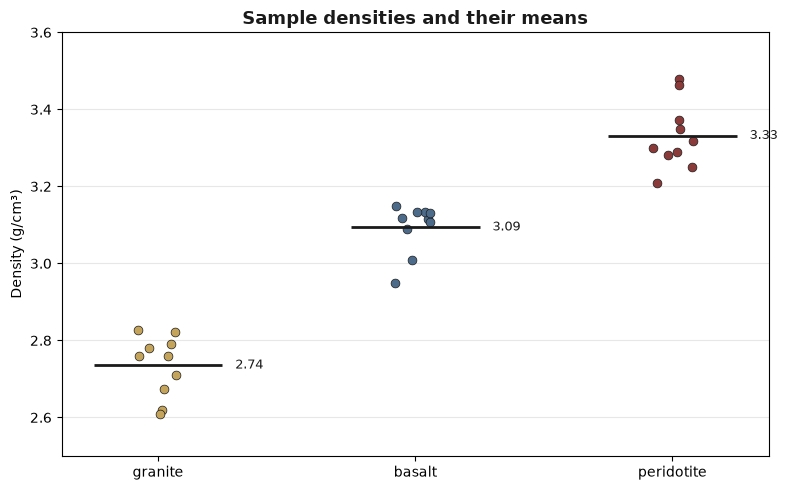

saved figures/part1_sample_densities.png


In [3]:
# One density per sample, then the mean of those ten values, matching
# the spreadsheet array formula SUM(mass/volume)/10.
samples = samples.copy()
samples["density_g_cm3"] = samples["mass_g"] / samples["volume_cm3"]

density_table = show_density_table(samples)
print()
# Keep the three means in a dict for later parts.
means = {}
for rock, grp in samples.groupby("rock", sort=False):
    means[rock] = mean_of_ratios(grp["mass_g"], grp["volume_cm3"])
    print(f"{rock:11s}  mean of ratios = {means[rock]:.6f} g/cm³")

# Individual samples as a strip plot, with the mean as a short bar.
fig, ax = plt.subplots(figsize=(8.0, 5.0))
order = ["granite", "basalt", "peridotite"]  # lightest to densest
rng = np.random.default_rng(0)  # fixed jitter, so the figure is reproducible
for i, rock in enumerate(order):
    dens = samples.loc[samples["rock"] == rock, "density_g_cm3"].to_numpy()
    x = np.full(len(dens), i, dtype=float) + rng.uniform(-0.08, 0.08, size=len(dens))
    ax.scatter(x, dens, s=40, c=ROCK_COLORS[rock], edgecolors="#1a1a1a",
               linewidths=0.5, zorder=3, label=rock)
    ax.hlines(means[rock], i - 0.25, i + 0.25, colors="#1a1a1a", lw=2, zorder=4)
    # Place the mean label to the right of the bar, not on top of the points.
    ax.text(i + 0.30, means[rock], f"{means[rock]:.2f}", ha="left",
            va="center", fontsize=9, color="#1a1a1a")

ax.set_xticks(range(len(order)))
ax.set_xticklabels(order)
ax.set_ylabel("Density (g/cm³)")
ax.set_ylim(2.5, 3.6)
ax.set_title("Sample densities and their means", **TITLE)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "part1_sample_densities.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


The spreadsheet averages are 2.7354 g/cm³ for granite, 3.0938 g/cm³ for basalt, and 3.3315 g/cm³ for peridotite. Granite is the lightest, then basalt, then peridotite — which is the order you would want if continents (granite) are to float higher in the mantle than ocean floors (basalt), and if the mantle (peridotite) is to be the "fluid" they float in. The ten samples of each type cluster tightly enough that the means are well separated; no sample of granite is as dense as any sample of peridotite. Rounded to one decimal place the means are 2.7, 3.1, and 3.3 g/cm³, which is how they often get written in a table. Part 3 will use the spreadsheet values as the primary inputs and will show, as a comparison, how those one-decimal roundings change the freeboards.


## Part 2 — Isostatic rebound at Hudson Bay

When the ice sheets of the last glacial period melted, a huge weight came off the crust. The surface, which had been pushed down, began to rise. Beaches that formed at sea level at some time in the past are now *stranded* above today's shoreline. Their height above present sea level, together with a radiocarbon age for when they were at sea level, is a clock of that rebound.

The next cell plots the Hudson Bay points from the spreadsheet: age (years before present) on the x-axis and height (meters) on the y-axis, the same axes the lab asked for. A first look at the cloud of points is enough to see whether the rise has been roughly steady or has been slowing down. The slope of any curve we later fit has units of meters per year — a rebound *rate*. A straight line would be a constant rate. A curve that flattens toward the present would be a rate that is slowing, which is what a viscous mantle approaching a new equilibrium would lead you to expect.


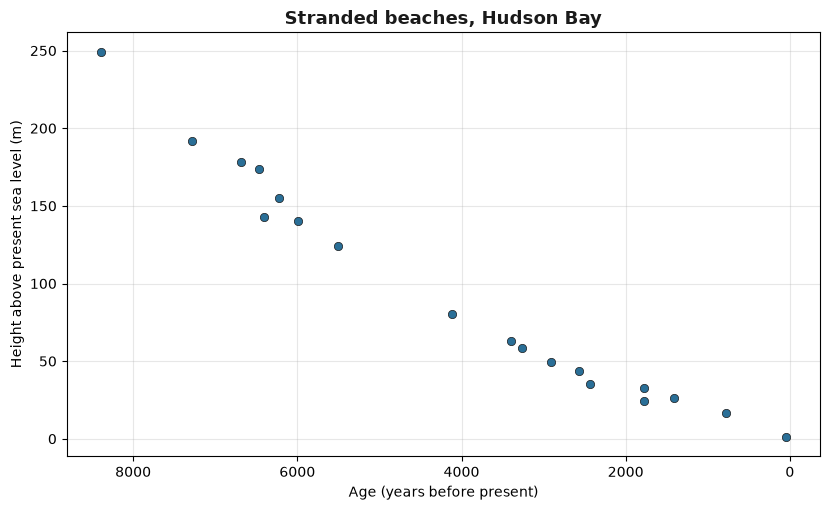

saved figures/part2_beaches.png
19 points, age 50–8393 yr BP, height 1.0–249.4 m


In [4]:
fig, ax = plt.subplots(figsize=(8.4, 5.2))
ax.scatter(
    beaches["age_yr_bp"], beaches["height_m"],
    s=36, c="#2A6F97", edgecolors="#1a1a1a", linewidths=0.5, zorder=3,
)
ax.set_xlabel("Age (years before present)")
ax.set_ylabel("Height above present sea level (m)")
ax.set_title("Stranded beaches, Hudson Bay", **TITLE)
ax.grid(True, alpha=0.3)
# Present on the right, older ages on the left, matching the usual
# way a rebound curve is drawn (and the Peltier illustration in the lab).
ax.invert_xaxis()
fig.tight_layout()
out = FIGDIR / "part2_beaches.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")
print(f"{len(beaches)} points, "
      f"age {beaches['age_yr_bp'].min():.0f}–{beaches['age_yr_bp'].max():.0f} yr BP, "
      f"height {beaches['height_m'].min():.1f}–{beaches['height_m'].max():.1f} m")


The beaches get lower as they get younger: a ~249 m shoreline at about 8400 years ago, down to 1 m at 50 years ago. The rise is not a perfect straight line. The points bow: steeper at older ages, flatter toward the present. That already suggests a slowing rebound. The next cell fits two models the lab asked for — a straight line and a polynomial — and compares them quantitatively. Excel's polynomial trendline is order 2 unless it is changed, so the polynomial here is a quadratic. That choice is noted because the workbook itself does not record the order.


## Linear and quadratic fits

A linear fit, $h = a\cdot\mathrm{age} + b$, has a single slope $a$ in m/yr: the average rebound rate over the whole record. A quadratic fit, $h = c_2\cdot\mathrm{age}^2 + c_1\cdot\mathrm{age} + c_0$, has a slope that changes with age. The local rate is the derivative $dh/d(\mathrm{age}) = 2c_2\cdot\mathrm{age} + c_1$, which is the rebound rate at that time (because age is measured backward from the present).

The next cell fits both models by least squares, plots them on the same axes as the data, and reports $R^2$ and the root-mean-square residual (RMSE) for each. Those two numbers are a compact way to talk about "which line follows the points more closely" without relying on a visual impression alone. The original lab also asked how much age uncertainty would be needed before the two fits became hard to tell apart; the cell after the plot looks at the gap between the two curves compared with the scatter around the quadratic, as a way to make that question quantitative. It does not stand in for the written discussion the lab asked for.


Linear fit:  h = a * age + b
  slope a = 0.028884 m/yr  (28.88 mm/yr)
  intercept b = -23.72 m
  R² = 0.9632,  RMSE = 13.55 m

Quadratic fit:  h = c2 * age² + c1 * age + c0
  coefficients c2, c1, c0 = 2.465853e-06, 8.262999e-03, 5.1696
  R² = 0.9932,  RMSE = 5.82 m
  rate at 8000 yr BP: 47.7 mm/yr
  rate at 1000 yr BP: 13.2 mm/yr
  rate at   50 yr BP: 8.5 mm/yr


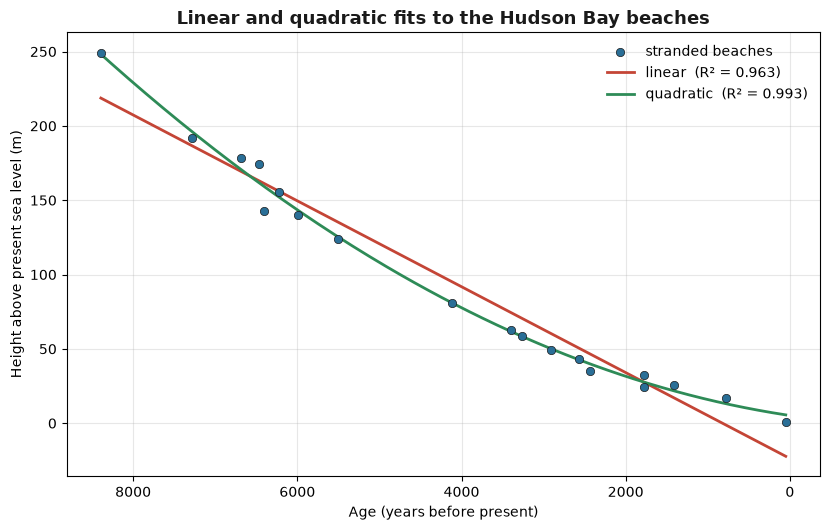

saved figures/part2_fits.png


In [5]:
age = beaches["age_yr_bp"].to_numpy()
height = beaches["height_m"].to_numpy()

# Least-squares polynomial fits. Degree 1 is a straight line;
# degree 2 is a quadratic (Excel's default polynomial trendline).
lin = np.polyfit(age, height, 1)
quad = np.polyfit(age, height, 2)
h_lin = np.polyval(lin, age)
h_quad = np.polyval(quad, age)

ss_tot = np.sum((height - height.mean()) ** 2)
r2_lin = 1.0 - np.sum((height - h_lin) ** 2) / ss_tot
r2_quad = 1.0 - np.sum((height - h_quad) ** 2) / ss_tot
rmse_lin = float(np.sqrt(np.mean((height - h_lin) ** 2)))
rmse_quad = float(np.sqrt(np.mean((height - h_quad) ** 2)))

# Instantaneous quadratic rate: dh/d(age) = 2 c2 age + c1, in m/yr.
def quad_rate(age_yr):
    return 2.0 * quad[0] * age_yr + quad[1]

print("Linear fit:  h = a * age + b")
print(f"  slope a = {lin[0]:.6f} m/yr  ({lin[0]*1000:.2f} mm/yr)")
print(f"  intercept b = {lin[1]:.2f} m")
print(f"  R² = {r2_lin:.4f},  RMSE = {rmse_lin:.2f} m")
print()
print("Quadratic fit:  h = c2 * age² + c1 * age + c0")
print(f"  coefficients c2, c1, c0 = {quad[0]:.6e}, {quad[1]:.6e}, {quad[2]:.4f}")
print(f"  R² = {r2_quad:.4f},  RMSE = {rmse_quad:.2f} m")
print(f"  rate at 8000 yr BP: {quad_rate(8000)*1000:.1f} mm/yr")
print(f"  rate at 1000 yr BP: {quad_rate(1000)*1000:.1f} mm/yr")
print(f"  rate at   50 yr BP: {quad_rate(50)*1000:.1f} mm/yr")

age_line = np.linspace(age.min(), age.max(), 200)
fig, ax = plt.subplots(figsize=(8.4, 5.4))
ax.scatter(age, height, s=36, c="#2A6F97", edgecolors="#1a1a1a",
           linewidths=0.5, zorder=3, label="stranded beaches")
ax.plot(age_line, np.polyval(lin, age_line), color="#C44536", lw=2,
        label=f"linear  (R² = {r2_lin:.3f})")
ax.plot(age_line, np.polyval(quad, age_line), color="#2E8B57", lw=2,
        label=f"quadratic  (R² = {r2_quad:.3f})")
ax.set_xlabel("Age (years before present)")
ax.set_ylabel("Height above present sea level (m)")
ax.set_title("Linear and quadratic fits to the Hudson Bay beaches", **TITLE)
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
ax.invert_xaxis()
fig.tight_layout()
out = FIGDIR / "part2_fits.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


The linear slope is 0.02888 m/yr, or 28.88 mm/yr — a useful single-number rebound rate, but it is an average over 8400 years. The quadratic follows the bow in the data more closely: $R^2$ rises from 0.963 to 0.993, and the RMSE falls from 13.55 m to 5.82 m. Its instantaneous rate is about 48 mm/yr at 8000 years ago and about 8.5 mm/yr at 50 years ago, which is the slowing that the raw points already suggested. The linear intercept is also slightly negative (−23.7 m at age zero), which is an awkward place for "present-day sea level" to sit; the quadratic intercept is +5.2 m. The next cell plots the residuals and the gap between the two curves, which is the natural scale for the lab's uncertainty question.


## Residuals and a scale for uncertainty

A residual is the vertical distance from a data point to a fitted curve, here in meters of height. If the residuals of the quadratic are already several meters, and the two fitted curves themselves are only a few meters apart at some ages, then a modest error in height — or the equivalent error in age, height-error divided by the local slope — would start to blur the distinction between the two models. The next cell plots those residuals against age, and prints the mean and maximum gap between the linear and quadratic curves, both in meters and as an equivalent age using the linear slope. Those computed scales are meant to inform the discussion the lab asked for, not to replace it.


Quadratic residual standard deviation: 5.98 m
Linear residual standard deviation:    13.92 m
Mean |linear − quadratic|:  9.17 m (equivalent age 317 yr at the linear slope)
Max  |linear − quadratic|:  29.53 m (equivalent age 1022 yr)


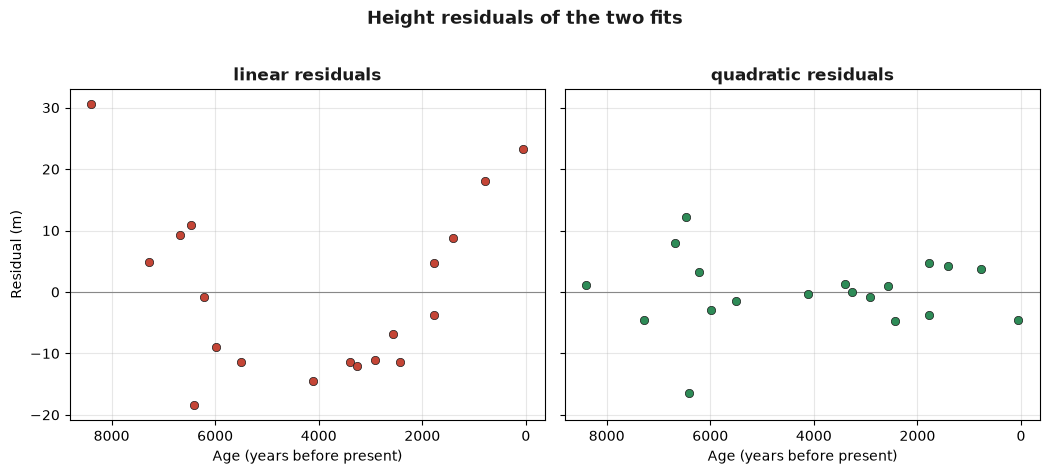

saved figures/part2_residuals.png


In [6]:
resid_lin = height - h_lin
resid_quad = height - h_quad
gap = np.abs(h_lin - h_quad)
equiv_age = gap / abs(lin[0])  # meters / (meters/year) = years

print(f"Quadratic residual standard deviation: {resid_quad.std(ddof=1):.2f} m")
print(f"Linear residual standard deviation:    {resid_lin.std(ddof=1):.2f} m")
print(f"Mean |linear − quadratic|:  {gap.mean():.2f} m "
      f"(equivalent age {equiv_age.mean():.0f} yr at the linear slope)")
print(f"Max  |linear − quadratic|:  {gap.max():.2f} m "
      f"(equivalent age {equiv_age.max():.0f} yr)")

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.6), sharey=True)
for ax, resid, name, color in (
    (axes[0], resid_lin, "linear residuals", "#C44536"),
    (axes[1], resid_quad, "quadratic residuals", "#2E8B57"),
):
    ax.axhline(0, color="#888888", lw=0.8)
    ax.scatter(age, resid, s=36, c=color, edgecolors="#1a1a1a",
               linewidths=0.5, zorder=3)
    ax.set_xlabel("Age (years before present)")
    ax.set_title(name, fontsize=12, fontweight="bold", color="#1a1a1a")
    ax.grid(True, alpha=0.3)
    ax.invert_xaxis()
axes[0].set_ylabel("Residual (m)")
fig.suptitle("Height residuals of the two fits", **TITLE, y=1.02)
fig.tight_layout()
out = FIGDIR / "part2_residuals.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


The quadratic residuals scatter by about ±6 m (standard deviation 5.98 m), with no strong leftover trend. The linear residuals are larger and systematically bowed — high in the middle of the record, low at the ends — which is what you see when a curve is fitted by a straight line. The two models differ from each other by 9.17 m on average and by up to 29.53 m, which at the linear slope of 28.88 mm/yr is an equivalent age of about 317 years on average and about 1020 years at the largest gap. How much age uncertainty would be "enough to make the two fits indistinguishable" is the written question; the numbers above are the ingredients for that comparison.


## Part 3 — Floating crust and Earth's two-level topography

Seismic evidence, quoted in the lab, gives a typical oceanic crust about 5 km thick and a typical continental crust about 30 km thick. Combined with the densities from Part 1, the floating-block equation from the setup says how much of each column sits above the mantle surface,

$$H_\mathrm{above} = T\frac{\rho_m - \rho_c}{\rho_m}.$$

Oceanic crust is represented by the basalt average, continental crust by the granite average, and the mantle by the peridotite average. The next cell computes those two freeboards from the spreadsheet densities, and also from the one-decimal rounded values (3.1, 2.7, and 3.3 g/cm³), so the effect of rounding is visible. The difference between the continental and oceanic freeboards is the model's prediction for how much higher average continents should sit than average ocean floors, and can be compared with the 4.53 km land-to-seafloor difference labeled on the lab figure (0.84 km average land height plus 3.69 km average ocean depth).


In [7]:
rho_b = means["basalt"]
rho_g = means["granite"]
rho_m = means["peridotite"]

# Primary results: spreadsheet (mean-of-ratios) densities.
h_basalt = freeboard(OCEAN_CRUST_KM, rho_b, rho_m)
h_granite = freeboard(CONTINENT_CRUST_KM, rho_g, rho_m)
step = h_granite - h_basalt

# Comparison: densities rounded to one decimal place (3.1, 2.7, 3.3).
rho_b_r, rho_g_r, rho_m_r = 3.1, 2.7, 3.3
h_basalt_r = freeboard(OCEAN_CRUST_KM, rho_b_r, rho_m_r)
h_granite_r = freeboard(CONTINENT_CRUST_KM, rho_g_r, rho_m_r)
step_r = h_granite_r - h_basalt_r

rows = [
    {
        "Densities": "spreadsheet averages",
        "ρ basalt": rho_b,
        "ρ granite": rho_g,
        "ρ mantle": rho_m,
        "H_above basalt (km)": h_basalt,
        "H_above granite (km)": h_granite,
        "Difference (km)": step,
    },
    {
        "Densities": "rounded to 1 decimal",
        "ρ basalt": rho_b_r,
        "ρ granite": rho_g_r,
        "ρ mantle": rho_m_r,
        "H_above basalt (km)": h_basalt_r,
        "H_above granite (km)": h_granite_r,
        "Difference (km)": step_r,
    },
    {
        "Densities": "lab figure (land − seafloor)",
        "ρ basalt": np.nan,
        "ρ granite": np.nan,
        "ρ mantle": np.nan,
        "H_above basalt (km)": np.nan,
        "H_above granite (km)": np.nan,
        "Difference (km)": FIGURE_STEP_KM,
    },
]
iso = pd.DataFrame(rows)
display(
    iso.style.format(
        {
            "ρ basalt": "{:.4f}",
            "ρ granite": "{:.4f}",
            "ρ mantle": "{:.4f}",
            "H_above basalt (km)": "{:.4f}",
            "H_above granite (km)": "{:.4f}",
            "Difference (km)": "{:.4f}",
        },
        na_rep="—",
    ).hide(axis="index")
)
print()
print(f"spreadsheet-density freeboards: "
      f"basalt {h_basalt:.4f} km, granite {h_granite:.4f} km, "
      f"difference {step:.4f} km")
print(f"lab figure land-to-seafloor step: {FIGURE_STEP_KM:.2f} km "
      f"({AVG_LAND_HEIGHT_KM} km land + {AVG_OCEAN_DEPTH_KM} km ocean)")


Densities,ρ basalt,ρ granite,ρ mantle,H_above basalt (km),H_above granite (km),Difference (km)
spreadsheet averages,3.0938,2.7354,3.3315,0.3567,5.3680,5.0112
rounded to 1 decimal,3.1000,2.7000,3.3000,0.3030,5.4545,5.1515
lab figure (land − seafloor),—,—,—,—,—,4.5300



spreadsheet-density freeboards: basalt 0.3567 km, granite 5.3680 km, difference 5.0112 km
lab figure land-to-seafloor step: 4.53 km (0.84 km land + 3.69 km ocean)


With the spreadsheet densities, 5 km of basalt has a freeboard of 0.3567 km, and 30 km of granite has a freeboard of 5.3680 km. The difference is 5.0112 km. That is the same order as the figure's 4.53 km step from average land to average ocean floor, which is the point of the comparison: a light, thick granite column and a heavier, thin basalt column, both floating in peridotite, naturally produce a two-level (bimodal) surface, with most land near sea level and most seafloor several kilometers down. The match is close but not exact — the floating-block difference is about half a kilometer larger than 4.53 km. The model is a two-block sketch: laboratory densities, average thicknesses, and no water layer, sediments, or density increase with depth. The point of the comparison is the order of magnitude and the bimodal pattern, not a perfect numerical match. Rounding each density to one decimal place gives freeboards of 0.3030 km and 5.4545 km, a difference of 5.1515 km, which is the arithmetic you get if you work from the one-decimal table values. The next cell draws the two blocks to scale, together with sea level placed 0.84 km below the top of the average continent, so the freeboards can be seen rather than only read.


## A to-scale look at the two floating columns

The next cell draws the 5 km basalt column and the 30 km granite column sitting in the mantle, using the spreadsheet-density freeboards. The horizontal line through the diagram is the mantle surface (the "waterline"). Sea level is drawn 0.84 km below the top of the continental column, the average land height labeled on the lab figure. The vertical scale is true kilometers; the block widths are schematic.


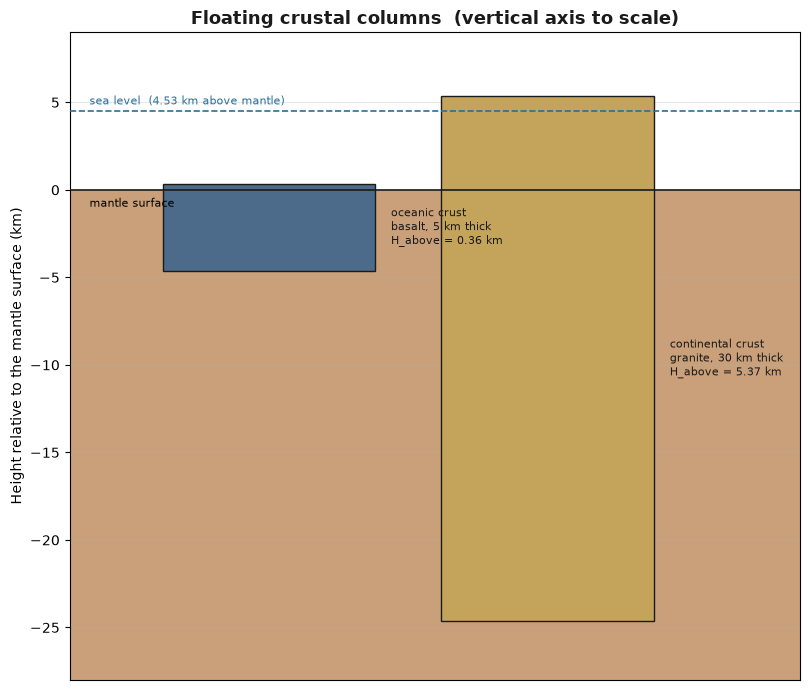

saved figures/part3_floating_blocks.png
sea level is 4.5280 km above the mantle surface
model ocean floor is 4.1712 km below that sea level


In [8]:
# Vertical axis is true kilometers. Block widths are schematic
# (equal aspect would make a 30 km column too thin to label).
# z = 0 is the mantle surface, positive upward.

fig, ax = plt.subplots(figsize=(8.2, 7.0))

z_min = -28
z_max = 9
ax.add_patch(Rectangle((-0.5, z_min), 5.5, -z_min,
                       facecolor="#C9A07A", edgecolor="none", zorder=0))

# (x_left, width, thickness, freeboard, color, name, detail)
blocks = [
    (0.2, 1.6, OCEAN_CRUST_KM, h_basalt, ROCK_COLORS["basalt"],
     "oceanic crust",
     f"basalt, {OCEAN_CRUST_KM:.0f} km thick\nH_above = {h_basalt:.2f} km"),
    (2.3, 1.6, CONTINENT_CRUST_KM, h_granite, ROCK_COLORS["granite"],
     "continental crust",
     f"granite, {CONTINENT_CRUST_KM:.0f} km thick\nH_above = {h_granite:.2f} km"),
]
for x, width, T, H, color, name, detail in blocks:
    # Top of the block is at z = H; the block extends downward by T.
    ax.add_patch(Rectangle((x, H - T), width, T,
                           facecolor=color, edgecolor="#1a1a1a", lw=1.0, zorder=2))
    # Labels sit to the right of each column, clear of the freeboard.
    ax.text(x + width + 0.12, H - T / 2, f"{name}\n{detail}",
            ha="left", va="center", fontsize=8, color="#1a1a1a")

# Mantle surface (the "waterline") and sea level.
# Sea level is 0.84 km below the top of the average continent.
z_sl = h_granite - AVG_LAND_HEIGHT_KM
ax.axhline(0, color="#1a1a1a", lw=1.2, zorder=3)
ax.text(-0.35, -0.45, "mantle surface", ha="left", va="top", fontsize=8)
ax.axhline(z_sl, color="#2A6F97", lw=1.2, ls="--", zorder=3)
ax.text(-0.35, z_sl + 0.2, f"sea level  ({z_sl:.2f} km above mantle)",
        ha="left", va="bottom", fontsize=8, color="#2A6F97")

ax.set_xlim(-0.5, 5.0)
ax.set_ylim(z_min, z_max)
ax.set_ylabel("Height relative to the mantle surface (km)")
ax.set_xticks([])
ax.set_title("Floating crustal columns  (vertical axis to scale)", **TITLE)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "part3_floating_blocks.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")
print(f"sea level is {z_sl:.4f} km above the mantle surface")
print(f"model ocean floor is {z_sl - h_basalt:.4f} km below that sea level")


The granite column stands much higher, and most of both columns sit below the mantle surface as a root. Sea level, once it is placed 0.84 km below the average continental surface, lies 4.5280 km above the mantle. In this dry model the basalt top (the model ocean floor) is only 0.3567 km above the mantle, about 4.17 km below that sea level, a little deeper than the figure's 3.69 km average ocean. The next calculation uses the same sea-level placement to ask a different question: if the Andes stand 5 km above sea level and are made of granite, how thick is that column?


## Thickness of the Andes

The lab gives the Andes an average elevation of 5 km above sea level and asks for the thickness of a granite column that stands that high. The hint is to find $H_\mathrm{above}$ first. From the previous section, average continental crust has a freeboard of 5.3680 km, and the lab figure puts average land 0.84 km above sea level, so sea level is 5.3680 − 0.84 = 4.5280 km above the mantle. The Andes, 5 km above sea level, then have

$$H_\mathrm{above}^\mathrm{Andes} = 4.5280 + 5 = 9.5280\,\mathrm{km}.$$

The thickness follows from the inverse floating-block equation,

$$T = H_\mathrm{above}\frac{\rho_m}{\rho_m - \rho_c}.$$

That extra height is balanced by an extra root: this is Airy isostasy. The next cell computes $T$ from the spreadsheet densities (and, for comparison, from the one-decimal densities).


In [9]:
# Sea level above the mantle, from the average continent's freeboard
# minus the figure's 0.84 km average land height.
z_sl = h_granite - AVG_LAND_HEIGHT_KM
h_andes = z_sl + ANDES_ELEVATION_KM
T_andes = thickness_from_freeboard(h_andes, rho_g, rho_m)
root_andes = T_andes - h_andes
root_continent = CONTINENT_CRUST_KM - h_granite

# Same arithmetic with the one-decimal densities, for comparison.
z_sl_r = h_granite_r - AVG_LAND_HEIGHT_KM
h_andes_r = z_sl_r + ANDES_ELEVATION_KM
T_andes_r = thickness_from_freeboard(h_andes_r, rho_g_r, rho_m_r)

andes_table = pd.DataFrame([
    {
        "Densities": "spreadsheet averages",
        "Sea level above mantle (km)": z_sl,
        "Andes H_above (km)": h_andes,
        "Andes thickness (km)": T_andes,
        "Andes root (km)": root_andes,
    },
    {
        "Densities": "rounded to 1 decimal",
        "Sea level above mantle (km)": z_sl_r,
        "Andes H_above (km)": h_andes_r,
        "Andes thickness (km)": T_andes_r,
        "Andes root (km)": T_andes_r - h_andes_r,
    },
])
display(
    andes_table.style.format("{:.4f}", subset=[
        "Sea level above mantle (km)",
        "Andes H_above (km)",
        "Andes thickness (km)",
        "Andes root (km)",
    ]).hide(axis="index")
)
print()
print(f"spreadsheet-density Andes: T = {T_andes:.4f} km, "
      f"root = {root_andes:.4f} km "
      f"(average continent root = {root_continent:.4f} km)")


Densities,Sea level above mantle (km),Andes H_above (km),Andes thickness (km),Andes root (km)
spreadsheet averages,4.5280,9.5280,53.2490,43.7210
rounded to 1 decimal,4.6145,9.6145,52.8800,43.2655



spreadsheet-density Andes: T = 53.2490 km, root = 43.7210 km (average continent root = 24.6320 km)


The Andes column comes out 53.2490 km thick with the spreadsheet densities — nearly twice the 30 km average continent, with a freeboard of 9.5280 km. Using the one-decimal densities instead gives 52.8800 km, a change of only a few tenths of a kilometer. The root (the part below the mantle surface) is 53.2490 − 9.5280 = 43.7210 km, much deeper than the average continent's 24.6320 km root. The next cell puts those three columns on one east–west cross-section across South America: Pacific ocean, Andes, the rest of the continent, Atlantic ocean, drawn to vertical scale, with sea level and the mantle surface as the two reference lines. The trench is sketched only as a notch in the seafloor; this lab does not give a trench thickness, so none is invented.


## A schematic east–west section across South America

The next cell draws the three granite and basalt thicknesses just computed, west to the left (Pacific) and east to the right (Atlantic), which is the usual map orientation. Horizontal distances are not to scale — South America is thousands of kilometers across, and these columns are tens of kilometers thick — but the vertical thicknesses, freeboards, sea level, and mantle surface are. The point of the sketch is the Airy root under the Andes and the thin oceanic crust on either side.


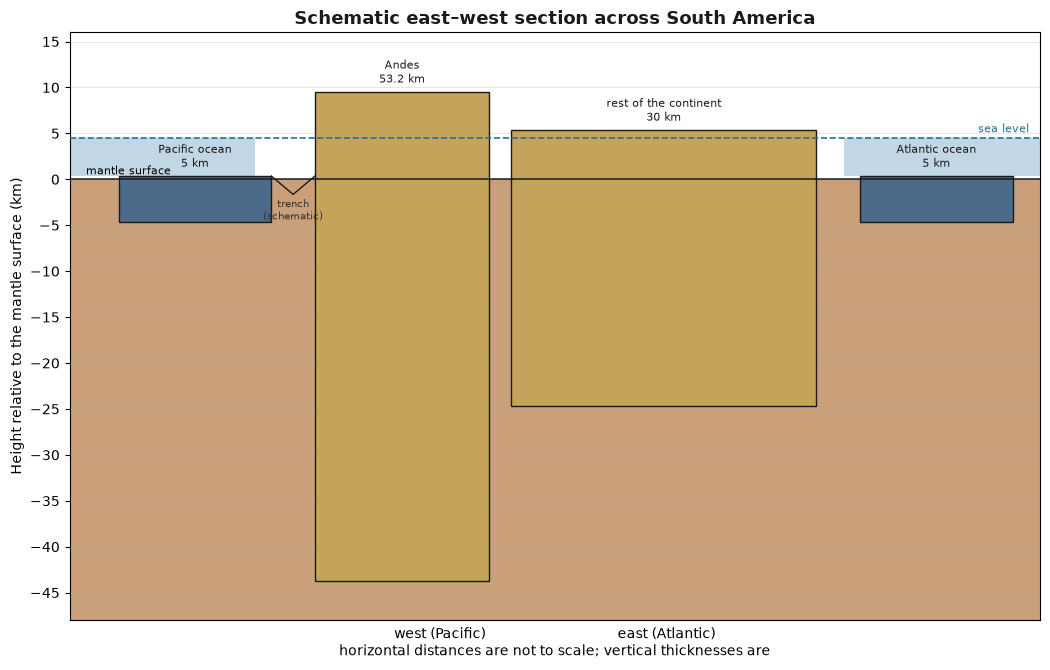

saved figures/part3_south_america_section.png


In [10]:
# West on the left (Pacific), east on the right (Atlantic).
# Vertical thicknesses are to scale; horizontal distances are not.

fig, ax = plt.subplots(figsize=(10.6, 6.8))

z_min = -48
z_max = 16
ax.add_patch(Rectangle((-0.4, z_min), 9.0, -z_min,
                       facecolor="#C9A07A", edgecolor="none", zorder=0))
# A light water wash between sea level and the ocean floor, both sides.
# (The dry-model ocean floor is at z = h_basalt.)
ax.add_patch(Rectangle((-0.4, h_basalt), 1.7, z_sl - h_basalt,
                       facecolor="#A9C7DB", edgecolor="none", zorder=1, alpha=0.7))
ax.add_patch(Rectangle((6.7, h_basalt), 1.8, z_sl - h_basalt,
                       facecolor="#A9C7DB", edgecolor="none", zorder=1, alpha=0.7))

# Columns: (x, width, thickness, freeboard, color, label)
# Widths are schematic; the vertical thicknesses are the computed km.
columns = [
    (0.05, 1.4, OCEAN_CRUST_KM, h_basalt, ROCK_COLORS["basalt"],
     f"Pacific ocean\n{OCEAN_CRUST_KM:.0f} km"),
    (1.85, 1.6, T_andes, h_andes, ROCK_COLORS["granite"],
     f"Andes\n{T_andes:.1f} km"),
    (3.65, 2.8, CONTINENT_CRUST_KM, h_granite, ROCK_COLORS["granite"],
     f"rest of the continent\n{CONTINENT_CRUST_KM:.0f} km"),
    (6.85, 1.4, OCEAN_CRUST_KM, h_basalt, ROCK_COLORS["basalt"],
     f"Atlantic ocean\n{OCEAN_CRUST_KM:.0f} km"),
]
for x, width, T, H, color, label in columns:
    ax.add_patch(Rectangle((x, H - T), width, T,
                           facecolor=color, edgecolor="#1a1a1a", lw=1.0, zorder=2))
    ax.text(x + width / 2, H + 0.6, label, ha="center", va="bottom",
            fontsize=8, color="#1a1a1a")

# A small schematic notch for a trench, not a computed depth.
trench_x = np.array([1.45, 1.65, 1.85])
trench_z = np.array([h_basalt, h_basalt - 2.0, h_basalt])
ax.plot(trench_x, trench_z, color="#1a1a1a", lw=1.0, zorder=3)
ax.text(1.65, h_basalt - 2.4, "trench\n(schematic)", ha="center", va="top",
        fontsize=7, color="#333333")

ax.axhline(0, color="#1a1a1a", lw=1.1, zorder=3)
ax.text(-0.25, 0.25, "mantle surface", ha="left", va="bottom", fontsize=8)
ax.axhline(z_sl, color="#2A6F97", lw=1.2, ls="--", zorder=3)
ax.text(8.4, z_sl + 0.3, "sea level", ha="right", va="bottom",
        fontsize=8, color="#2A6F97")

ax.set_xlim(-0.4, 8.5)
ax.set_ylim(z_min, z_max)
ax.set_ylabel("Height relative to the mantle surface (km)")
ax.set_yticks(np.arange(-45, 20, 5))
ax.set_xticks([])
ax.set_xlabel("west (Pacific)                                 east (Atlantic)\n"
              "horizontal distances are not to scale; vertical thicknesses are")
ax.set_title("Schematic east–west section across South America", **TITLE)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "part3_south_america_section.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


The Andes stand 5 km above sea level because the granite column there is about 53 km thick, with a root that reaches much deeper into the mantle than the root under the rest of the continent. The ocean on both sides is a thin basalt lid. That is the Airy picture in one diagram: high topography, deep root; low topography, thin crust. A Pratt picture would have kept the base of the crust flat and changed the density instead; that is not what was computed here.


## Extra (not part of the lab): two ways to average density

The original lab stops at the floating-block calculations above. This section is optional, and is here for a question that comes up naturally from the spreadsheet.

The workbook's average is the mean of the ten sample densities, $\frac{1}{10}\sum (m_i/V_i)$. The bulk density of the same ten samples, $\sum m / \sum V$, is not the same thing: it weights larger samples more. If someone asks "why not just add up the mass and add up the volume," the next cell shows both numbers side by side. The check cell uses the mean of ratios, because that is the formula in the spreadsheet.


Rock,Mean of ratios (g/cm³),Bulk density Σm/ΣV (g/cm³),Difference (g/cm³)
basalt,3.0938,3.0992,+0.0055
granite,2.7354,2.7401,+0.0048
peridotite,3.3315,3.3133,-0.0182


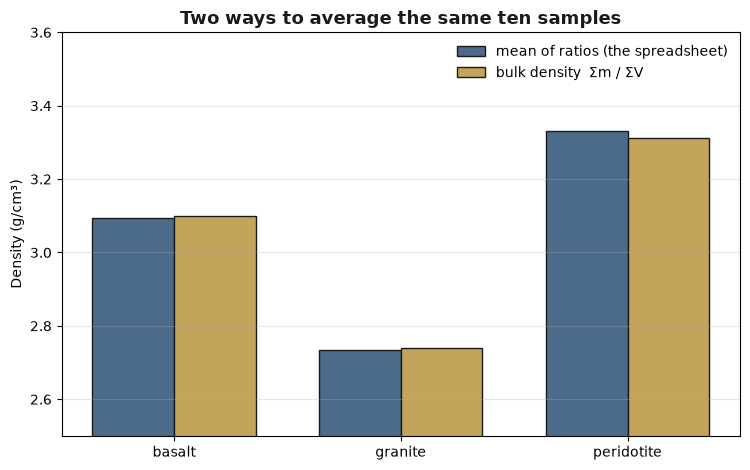

saved figures/extra_two_averages.png


In [11]:
rows = []
for rock, grp in samples.groupby("rock", sort=False):
    mor = mean_of_ratios(grp["mass_g"], grp["volume_cm3"])
    bulk = bulk_density(grp["mass_g"], grp["volume_cm3"])
    rows.append({
        "Rock": rock,
        "Mean of ratios (g/cm³)": mor,
        "Bulk density Σm/ΣV (g/cm³)": bulk,
        "Difference (g/cm³)": bulk - mor,
    })
cmp = pd.DataFrame(rows)
display(
    cmp.style.format(
        {
            "Mean of ratios (g/cm³)": "{:.4f}",
            "Bulk density Σm/ΣV (g/cm³)": "{:.4f}",
            "Difference (g/cm³)": "{:+.4f}",
        }
    ).hide(axis="index")
)

fig, ax = plt.subplots(figsize=(7.6, 4.8))
x = np.arange(len(cmp))
w = 0.36
ax.bar(x - w / 2, cmp["Mean of ratios (g/cm³)"], width=w,
       color="#4C6B8A", edgecolor="#1a1a1a", label="mean of ratios (the spreadsheet)")
ax.bar(x + w / 2, cmp["Bulk density Σm/ΣV (g/cm³)"], width=w,
       color="#C4A35A", edgecolor="#1a1a1a", label="bulk density  Σm / ΣV")
ax.set_xticks(x)
ax.set_xticklabels(cmp["Rock"])
ax.set_ylabel("Density (g/cm³)")
ax.set_ylim(2.5, 3.6)
ax.set_title("Two ways to average the same ten samples", **TITLE)
ax.legend(frameon=False)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "extra_two_averages.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


The two averages differ only in the third decimal place (basalt 3.0938 g/cm³ as a mean of ratios and 3.0992 g/cm³ as a bulk ratio; granite 2.7354 versus 2.7401; peridotite 3.3315 versus 3.3133). The spreadsheet formula is unambiguously the mean of ratios, and that is what the check cell will use. The bulk ratio is just a reminder that "average density" can mean two slightly different things. For peridotite the bulk ratio is actually a little *lower* than the mean of ratios, because some of the larger samples are a little less dense; the two averages need not sit on the same side of each other for every rock type.


## Check against the Excel workbook

The next cell loads `data/excel_reference.xlsx` with `openpyxl` (`data_only=True`). That small file holds the three average-density values stored in the completed lab spreadsheet (the array formulas `SUM(mass/volume)/10` on the Part 1 sheet). Each assertion requires the relative difference to be at most $10^{-6}$. The beach table is also checked against the CSV, row by row, so the Part 2 inputs match the workbook. Part 3 has no calculated cells in the spreadsheet; those results are the floating-block evaluations already computed above.


In [12]:
from openpyxl import load_workbook

def assert_close(name, got, expected, rtol=1e-6):
    """Fail if the relative difference is larger than rtol."""
    got = float(got)
    expected = float(expected)
    rel = abs(got - expected) / abs(expected) if expected != 0 else abs(got)
    assert rel <= rtol, (
        f"{name}: got {got}, expected {expected}, relative error {rel:.3e}"
    )
    print(f"ok  {name}: {got}   (relative error {rel:.2e})")


# data_only=True reads the stored numeric results, not the formulas.
wb = load_workbook(DATADIR / "excel_reference.xlsx", data_only=True)
ws = wb["densities"]
headers = [cell.value for cell in ws[1]]
excel = {}
for row in ws.iter_rows(min_row=2, values_only=True):
    rec = dict(zip(headers, row))
    excel[rec["rock"]] = rec["excel_average_density_g_cm3"]
wb.close()

for rock in ["basalt", "granite", "peridotite"]:
    assert_close(
        f"{rock} mean density (g/cm³)",
        means[rock],
        excel[rock],
    )

# The 19 beach points should also match the completed Part 2 sheet,
# which is stored in the trimmed CSV used above.
src_beaches = load_beaches()
assert len(src_beaches) == 19, f"expected 19 beaches, got {len(src_beaches)}"
assert src_beaches.equals(beaches), "beach table does not match the loaded CSV"
print("ok  19 Hudson Bay beach points match data/hudson_bay_beaches.csv")

print()
print("All checks passed: Python densities match the Excel workbook to 1e-6 relative.")


ok  basalt mean density (g/cm³): 3.093778865578866   (relative error 2.87e-16)
ok  granite mean density (g/cm³): 2.735365800865801   (relative error 0.00e+00)
ok  peridotite mean density (g/cm³): 3.331474747474748   (relative error 0.00e+00)
ok  19 Hudson Bay beach points match data/hudson_bay_beaches.csv

All checks passed: Python densities match the Excel workbook to 1e-6 relative.


If the cell above printed `ok` for every density and finished with "All checks passed," the Python mean-of-ratios densities match the completed Excel workbook to a relative tolerance of $10^{-6}$, and the 19 beach points match the Part 2 sheet. The residual differences on the densities are at the level of floating-point rounding, not a disagreement in method.
